In [332]:
# importing
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder,KBinsDiscretizer,PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor,plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, recall_score, precision_score, mean_squared_error, RocCurveDisplay
from sklearn.metrics._scorer import _SCORERS

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer

import category_encoders as ce

import warnings
warnings.filterwarnings('ignore')

# Classification

In [333]:
# import dataset
bankloan = pd.read_csv('bankloan.csv')
bankloan.head()

,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
0,41,3,17,12,176,9.3,11.359392,5.008608,1
1,27,1,10,6,31,17.3,1.362202,4.000798,0
2,40,1,15,14,55,5.5,0.856075,2.168925,0
3,41,1,15,14,120,2.9,2.658720,0.821280,0
4,24,2,2,0,28,17.3,1.787436,3.056564,1


In [334]:
# feature selection
feature = ['employ','debtinc','creddebt','othdebt']
target = ['default']

X = bankloan[feature]
y = bankloan[target]

In [335]:
# data split
X_train_val, X_test, y_train_val, y_test = train_test_split(
X,
y,
test_size = 0.2,
random_state = 2020
)

In [336]:
# prepare all model
logreg = LogisticRegression(solver = 'liblinear', random_state = 2020)
knn = KNeighborsClassifier(n_neighbors = 3)
tree = DecisionTreeClassifier(criterion='entropy', max_depth = 3)

In [337]:
# define the fold for Cross-Validation
skfold = StratifiedKFold(n_splits = 5)

logreg_cv = cross_val_score(estimator = logreg, X = X_train_val, y = y_train_val, cv = skfold)
knn_cv = cross_val_score(estimator = knn, X = X_train_val, y = y_train_val, cv = skfold)
tree_cv = cross_val_score(estimator = tree, X = X_train_val, y = y_train_val, cv = skfold)


In [338]:
# print the validation score
print('CV for logreg:', logreg_cv)
print('CV for knn:', knn_cv)
print('CV for tree:', tree_cv)

CV for logreg: [0.77678571 0.71428571 0.77678571 0.88392857 0.82142857]
CV for knn: [0.72321429 0.70535714 0.75       0.70535714 0.76785714]
CV for tree: [0.75892857 0.72321429 0.78571429 0.75       0.76785714]


In [339]:
# print the validation score mean as representative validation score
print('CV for logreg validation: ', logreg_cv.mean(),', and the standard deviation: ',logreg_cv.std())
print('CV for knn validation: ', knn_cv.mean(),', and the standard deviation: ',knn_cv.std())
print('CV for tree validation: ', tree_cv.mean(),', and the standard deviation: ',tree_cv.std())

CV for logreg validation:  0.7946428571428571 , and the standard deviation:  0.05618618829482953
CV for knn validation:  0.7303571428571429 , and the standard deviation:  0.024872121923543065
CV for tree validation:  0.7571428571428571 , and the standard deviation:  0.020671137326411123


In [340]:
# see the another evaluation metrics : recall
skfold = StratifiedKFold(n_splits = 5)

logreg_cv = cross_val_score(estimator = logreg, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'recall')
knn_cv = cross_val_score(estimator = knn, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'recall')
tree_cv = cross_val_score(estimator = tree, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'recall')


In [341]:
# print the validation recall score mean as representative validation recall score
print('CV for logreg recall: ', logreg_cv.mean(),', and the standard deviation: ',logreg_cv.std())
print('CV for knn recall: ', knn_cv.mean(),', and the standard deviation: ',knn_cv.std())
print('CV for tree recall: ', tree_cv.mean(),', and the standard deviation: ',tree_cv.std())

CV for logreg recall:  0.45073891625615764 , and the standard deviation:  0.12332992175989038
CV for knn recall:  0.37463054187192124 , and the standard deviation:  0.05713223954356393
CV for tree recall:  0.3204433497536946 , and the standard deviation:  0.17616675459364586


In [342]:
# see the another evaluation metrics : precision
skfold = StratifiedKFold(n_splits = 5)

logreg_cv = cross_val_score(estimator = logreg, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'precision')
knn_cv = cross_val_score(estimator = knn, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'precision')
tree_cv = cross_val_score(estimator = tree, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'precision')


In [343]:
# print the validation precision score mean as representative validation precision score
print('CV for logreg precision: ', logreg_cv.mean(),', and the standard deviation: ',logreg_cv.std())
print('CV for knn precision: ', knn_cv.mean(),', and the standard deviation: ',knn_cv.std())
print('CV for tree precision: ', tree_cv.mean(),', and the standard deviation: ',tree_cv.std())

CV for logreg precision:  0.6698548510313216 , and the standard deviation:  0.14713109729770152
CV for knn precision:  0.4807398870479366 , and the standard deviation:  0.06564857763677731
CV for tree precision:  0.6457366946778711 , and the standard deviation:  0.1886525640531097


In [344]:
# see the another evaluation metrics : f1
skfold = StratifiedKFold(n_splits = 5)

logreg_cv = cross_val_score(estimator = logreg, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'f1')
knn_cv = cross_val_score(estimator = knn, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'f1')
tree_cv = cross_val_score(estimator = tree, X = X_train_val, y = y_train_val, cv = skfold, scoring = 'f1')


In [345]:
# print the validation f1 score mean as representative validation f1 score
print('CV for logreg f1: ', logreg_cv.mean(),', and the standard deviation: ',logreg_cv.std())
print('CV for knn f1: ', knn_cv.mean(),', and the standard deviation: ',knn_cv.std())
print('CV for tree f1: ', tree_cv.mean(),', and the standard deviation: ',tree_cv.std())

CV for logreg f1:  0.5274945296038804 , and the standard deviation:  0.11690268344752333
CV for knn f1:  0.41556252151609047 , and the standard deviation:  0.03106703837852427
CV for tree f1:  0.3725540444880068 , and the standard deviation:  0.1384358981262033


In [346]:
# model performance in Test : knn
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train_val,y_train_val)
y_pred = knn.predict(X_test)

# show the evaluation metrics
print('recall: ',recall_score(y_test,y_pred))
print('precision: ',precision_score(y_test,y_pred))
print('F1-Score: ',f1_score(y_test,y_pred))

recall:  0.5897435897435898
precision:  0.575
F1-Score:  0.5822784810126582


In [347]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.83      0.84       101
           1       0.57      0.59      0.58        39

    accuracy                           0.76       140
   macro avg       0.71      0.71      0.71       140
weighted avg       0.77      0.76      0.77       140



In [348]:
# model performance in Test : logreg
logreg = LogisticRegression(solver = 'liblinear', random_state = 2020)
logreg.fit(X_train_val,y_train_val)
y_pred = logreg.predict(X_test)

# show the evaluation metrics
print('recall: ',recall_score(y_test,y_pred))
print('precision: ',precision_score(y_test,y_pred))
print('F1-Score: ',f1_score(y_test,y_pred))

recall:  0.5384615384615384
precision:  0.7241379310344828
F1-Score:  0.6176470588235294


In [349]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.92      0.88       101
           1       0.72      0.54      0.62        39

    accuracy                           0.81       140
   macro avg       0.78      0.73      0.75       140
weighted avg       0.81      0.81      0.81       140



In [350]:
# model performance in Test : tree
tree = tree = DecisionTreeClassifier(criterion='entropy', max_depth = 3)
tree.fit(X_train_val,y_train_val)
y_pred = tree.predict(X_test)

# show the evaluation metrics
print('recall: ',recall_score(y_test,y_pred))
print('precision: ',precision_score(y_test,y_pred))
print('F1-Score: ',f1_score(y_test,y_pred))

recall:  0.5897435897435898
precision:  0.6388888888888888
F1-Score:  0.6133333333333333


In [351]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.87      0.86       101
           1       0.64      0.59      0.61        39

    accuracy                           0.79       140
   macro avg       0.74      0.73      0.74       140
weighted avg       0.79      0.79      0.79       140



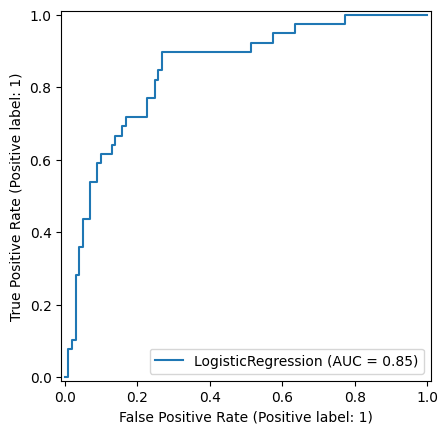

In [352]:
# plot the ROC Curve, for each model. higher AUC index, better model
# RocCurveDisplay.from_estimator(knn, X_test, y_test)
RocCurveDisplay.from_estimator(logreg, X_test, y_test)
# RocCurveDisplay.from_estimator(tree, X_test, y_test)

# Cross Validation

In [353]:
# apply cross validation on bankloan
X = bankloan[feature]
y = bankloan[target]

In [354]:
# Simple Parameter Tuning
X_train_val, X_test, y_train_val, y_test = train_test_split(
X,
y,
test_size = 0.2,
random_state = 2020
)

In [355]:
# regularization with C
hyperparam_c = [1000,500,100,50,10,5,1,0.1,0.5,0.01,0.05,0.001,0.005,0.0001,0.0005]
skfold = StratifiedKFold(n_splits=2)

best_score = 0
cv_score_validation_fold = []

for i in hyperparam_c:
    logreg = LogisticRegression(C=i, solver='liblinear',random_state=2020)
    cv_score = cross_val_score(logreg, X_train_val,y_train_val, cv=skfold, scoring = 'f1').mean()
    cv_score_validation_fold.append(cv_score)

    if cv_score > best_score:
        best_score = cv_score
        best_params = {'C':i}


In [356]:
# show best cv and params
print('best f1 score:', best_score)
print('best params:', best_params)

best f1 score: 0.523690932311622
best params: {'C': 0.1}


In [357]:
# predict without parameter from CV
logreg = LogisticRegression(solver = 'liblinear')
logreg.fit(X_train_val,y_train_val)
y_pred = logreg.predict(X_test)
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.84      0.92      0.88       101
           1       0.72      0.54      0.62        39

    accuracy                           0.81       140
   macro avg       0.78      0.73      0.75       140
weighted avg       0.81      0.81      0.81       140



In [358]:
# predict parameter from CV, optimizing precision
logreg = LogisticRegression(solver = 'liblinear',C=0.1)
logreg.fit(X_train_val,y_train_val)
y_pred = logreg.predict(X_test)
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.83      0.91      0.87       101
           1       0.69      0.51      0.59        39

    accuracy                           0.80       140
   macro avg       0.76      0.71      0.73       140
weighted avg       0.79      0.80      0.79       140



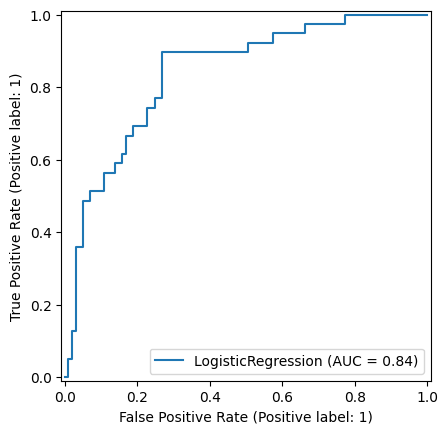

In [359]:
RocCurveDisplay.from_estimator(logreg, X_test, y_test)

after hyperparameter tuning, F1 score seems decreasing from 0.62 to 0.59. 
This can be happen because :
1. the improvement in the cross validation score is INSIGNIFICANT
1. the choice of hyperparameter resulted in overfitting/unstable model

Solution :
1. changes the model
1. more feature engineering
1. add another hyperprameter, (we are gonna try this)

In [360]:
# GridSearchCV hyperparameter tuning - be careful for the computation
hyperparam_space = {
    'C':[1000, 500, 100, 50, 10, 5, 1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001], # benck mark 1 C = 1 bench mark 2 C = 0.1
    'max_iter':[100, 200, 300, 400, 500, 1000] # bench mark max_iter = 100
}

1. CV for 5 folds
1. C for 15 combinations 
1. max_iter for 6 combinations

in total, the model will be trained 450 times, with 90 models created.

In [361]:
skfold = StratifiedKFold(n_splits = 5)

logreg = LogisticRegression(solver = 'liblinear', random_state = 2020)

grid_search = GridSearchCV(
    logreg, # model to tune
    param_grid = hyperparam_space, # hyperparameter space
    cv = skfold, # evaluation method
    scoring = 'f1', # metrics
    n_jobs = -1 # use all cores (exploit your laptop CPU)
)

In [362]:
# grid search fitting
grid_search.fit(X_train_val, y_train_val)

/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:1310: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:1310: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:1310: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:1310: DataConversionWarning: A column-vector y was passed when a 1d array was expec

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
             estimator=LogisticRegression(random_state=2020,
                                          solver='liblinear'),
             n_jobs=-1,
             param_grid={'C': [1000, 500, 100, 50, 10, 5, 1, 0.5, 0.1, 0.05,
                               0.01, 0.005, 0.001, 0.0005, 0.0001],
                         'max_iter': [100, 200, 300, 400, 500, 1000]},
             scoring='f1')

In [363]:
# show best score and the param index
print('best score',grid_search.best_score_)
print('best param',grid_search.best_params_)

best score 0.5546664724164725
best param {'C': 0.1, 'max_iter': 100}


In [364]:
# show all process
pd.DataFrame(grid_search.cv_results_).sort_values(by='rank_test_score',ascending=True)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_max_iter,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
48,0.007636,0.002031,0.017060,0.003388,0.1000,100,"{'C': 0.1, 'max_iter': 100}",0.48,0.53125,0.409091,0.730769,0.622222,0.554666,0.112153,1
49,0.008802,0.001300,0.017099,0.001723,0.1000,200,"{'C': 0.1, 'max_iter': 200}",0.48,0.53125,0.409091,0.730769,0.622222,0.554666,0.112153,1
50,0.007082,0.000311,0.018278,0.005870,0.1000,300,"{'C': 0.1, 'max_iter': 300}",0.48,0.53125,0.409091,0.730769,0.622222,0.554666,0.112153,1
51,0.007812,0.001361,0.016285,0.001259,0.1000,400,"{'C': 0.1, 'max_iter': 400}",0.48,0.53125,0.409091,0.730769,0.622222,0.554666,0.112153,1
52,0.007932,0.000681,0.017397,0.003374,0.1000,500,"{'C': 0.1, 'max_iter': 500}",0.48,0.53125,0.409091,0.730769,0.622222,0.554666,0.112153,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,0.007819,0.001717,0.016578,0.001482,0.0001,100,"{'C': 0.0001, 'max_iter': 100}",0.00,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,85
85,0.008499,0.002127,0.015765,0.001082,0.0001,200,"{'C': 0.0001, 'max_iter': 200}",0.00,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,85
86,0.007201,0.000413,0.018572,0.003905,0.0001,300,"{'C': 0.0001, 'max_iter': 300}",0.00,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,85
87,0.007142,0.000341,0.015803,0.002007,0.0001,400,"{'C': 0.0001, 'max_iter': 400}",0.00,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,85


This method still resulted in C = 0.05 max_iter = 100 which is basically the same. so no effect in adding max_iter. 
Conclusion:
1. We can use another method
1. more Feature Engineering on X

# Regression

In [365]:
tips = sns.load_dataset('tips')

In [366]:
# feature selection
X = pd.get_dummies(tips.drop('tip', axis = 1))
y = tips['tip']

In [367]:
# data split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, 
    y,
    test_size = 0.2, 
    random_state = 2020)

In [368]:
# import model
tree = DecisionTreeRegressor(criterion = 'squared_error', max_depth = 5, random_state = 2020)
linreg = LinearRegression()

In [369]:
# CV for tree model
model_cv = cross_val_score(tree,X_train_val,y_train_val,scoring='neg_mean_squared_error')

cross_val_score.scoring not providing mean_squared_error, see documentations by type '?cross_val_score'

In [370]:
# show metrics for tree
print('CV score',model_cv)
print('CV score mean',model_cv.mean())
print('CV score std',model_cv.std())

CV score [-1.0686013  -0.97814478 -1.77873212 -1.19898146 -1.19188762]
CV score mean -1.2432694552627068
CV score std 0.28004351146399903


In [371]:
# CV for linear regression
model_cv = cross_val_score(linreg, X_train_val, y_train_val, scoring = 'neg_mean_squared_error')

In [372]:
# show metrics for linear regression
print('CV score',model_cv)
print('CV score mean',model_cv.mean())
print('CV score std',model_cv.std())

CV score [-0.87304358 -0.84277215 -1.05989713 -1.77937311 -1.10502143]
CV score mean -1.1320214803006707
CV score std 0.3393316319526613


In [373]:
# model fitting : tree
tree = DecisionTreeRegressor(criterion = 'squared_error', max_depth = 5,random_state=2020)
tree.fit(X_train_val,y_train_val)

DecisionTreeRegressor(max_depth=5, random_state=2020)

In [374]:
# tree predict and calculate mse
y_pred = tree.predict(X_test)
print(mean_squared_error(y_test,y_pred))

1.4808803946104496


<Axes: ylabel='tip'>

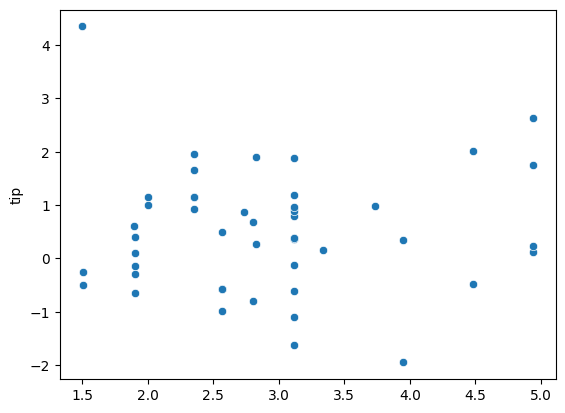

In [375]:
# plot
residuals = y_test - y_pred

sns.scatterplot(x = y_pred, y = residuals)

In [376]:
# hyperparameter tuning
hyperparam_space = {
    'min_samples_leaf':[1,5,10,15,20,50], # benck mark min_samples_leaf = 1
    'max_depth':[2,3,4,5,6,7], # bench mark max_depth = 5
    'criterion':['squared_error','absolute_error']
}

1. min_samples_leaf  6 hyperparameters
1. max_depht 5 hyperparameters
1. CV 5 fold
<br>
so, this step will train model 6*5*5 = 150 times 

In [377]:
tree_rs = DecisionTreeRegressor(criterion = 'squared_error', max_depth = 5, random_state = 2020)

randomized_search = RandomizedSearchCV(
    tree_rs, # model to tune
    param_distributions = hyperparam_space, # hyperparameter space
    n_iter = 20, # iterations
    cv = 5, # evaluation method
    scoring = 'neg_mean_squared_error', # metrics
    random_state = 2020,
    n_jobs = -1 # use all cores
)

In [378]:
randomized_search.fit(X_train_val, y_train_val)

RandomizedSearchCV(cv=5,
                   estimator=DecisionTreeRegressor(max_depth=5,
                                                   random_state=2020),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'criterion': ['squared_error',
                                                      'absolute_error'],
                                        'max_depth': [2, 3, 4, 5, 6, 7],
                                        'min_samples_leaf': [1, 5, 10, 15, 20,
                                                             50]},
                   random_state=2020, scoring='neg_mean_squared_error')

In [379]:
print('best score',randomized_search.best_score_)
print('best param',randomized_search.best_params_)

best score -0.9829038972124049
best param {'min_samples_leaf': 1, 'max_depth': 4, 'criterion': 'squared_error'}


In [380]:
pd.DataFrame(randomized_search.cv_results_).sort_values(by='rank_test_score',ascending=True) # 19 samples from randomized search

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_min_samples_leaf,param_max_depth,param_criterion,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
6,0.007497,0.003218,0.006028,0.002837,1,4,squared_error,"{'min_samples_leaf': 1, 'max_depth': 4, 'crite...",-0.771622,-0.665101,-1.593723,-1.029129,-0.854944,-0.982904,0.327795,1
9,0.007589,0.002056,0.004601,0.001716,1,2,squared_error,"{'min_samples_leaf': 1, 'max_depth': 2, 'crite...",-0.816130,-0.882642,-1.424336,-1.108872,-0.924132,-1.031222,0.219261,2
0,0.010435,0.002012,0.019120,0.029618,1,2,absolute_error,"{'min_samples_leaf': 1, 'max_depth': 2, 'crite...",-0.738330,-0.851707,-1.323954,-1.509013,-1.356648,-1.155931,0.303358,3
12,0.006108,0.000832,0.004411,0.001020,20,7,squared_error,"{'min_samples_leaf': 20, 'max_depth': 7, 'crit...",-0.870686,-0.765451,-1.294051,-1.731356,-1.297124,-1.191733,0.345704,4
13,0.008614,0.001045,0.003633,0.000192,10,3,absolute_error,"{'min_samples_leaf': 10, 'max_depth': 3, 'crit...",-0.766951,-0.655642,-1.331518,-2.316210,-1.005492,-1.215163,0.597288,5
3,0.015732,0.006306,0.008256,0.008681,20,2,absolute_error,"{'min_samples_leaf': 20, 'max_depth': 2, 'crit...",-0.722048,-1.093600,-1.182453,-1.955167,-1.356648,-1.261983,0.403899,6
19,0.007281,0.000658,0.003326,0.001143,15,2,absolute_error,"{'min_samples_leaf': 15, 'max_depth': 2, 'crit...",-0.722048,-1.093600,-1.208277,-1.955167,-1.356648,-1.267148,0.403013,7
4,0.016095,0.010713,0.008350,0.008731,5,2,absolute_error,"{'min_samples_leaf': 5, 'max_depth': 2, 'crite...",-0.722048,-1.093600,-1.215538,-1.960931,-1.356648,-1.269753,0.404778,8
8,0.008948,0.002966,0.006901,0.003214,20,4,absolute_error,"{'min_samples_leaf': 20, 'max_depth': 4, 'crit...",-0.805774,-1.082392,-1.204603,-1.997315,-1.332621,-1.284541,0.396694,9
10,0.008911,0.001573,0.003738,0.000253,15,3,absolute_error,"{'min_samples_leaf': 15, 'max_depth': 3, 'crit...",-0.743851,-1.105260,-1.122205,-2.278567,-1.254818,-1.300940,0.517391,10


In [381]:
# performance before hyperparameter tuning
tree = DecisionTreeRegressor(criterion = 'squared_error', max_depth = 5, random_state=2020)
tree.fit(X_train_val,y_train_val)
y_pred = tree.predict(X_test)
print(mean_squared_error(y_test,y_pred))

1.4808803946104496


In [382]:
# performance after hyperparameter tuning
tree_final = randomized_search.best_estimator_
tree_final.fit(X_train_val,y_train_val)
y_pred = tree_final.predict(X_test)
print(mean_squared_error(y_test,y_pred))

1.3093536770005814


Hyperparameter tuning decrease mse from 1.48 to 1.31